# Automated Skin Disease Detection from Dermoscopic Images with Explainability Analysis
**Author:** Tashmika Pillay | **Supervisor:** Prof Serestina Viriri  
**Dataset:** HAM10000 | **University of KwaZulu-Natal**

---

## Research Phases
- **Phase 1** — Dataset and Preprocessing
- **Phase 2** — Architecture Design, Implementation and Evaluation
- **Phase 3** — Explainability Analysis (Grad-CAM, SHAP, Attention Maps)
- **Phase 4** — Ablation Study
- **Phase 5** — Few-Shot and Zero-Shot Learning (Exploratory)

## Environment Setup

In [ ]:
!pip install -q grad-cam shap timm scikit-learn torchmetrics
print('Done.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 46.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 23.6 MB/s eta 0:00:00
Done.


In [ ]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models

from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, balanced_accuracy_score, cohen_kappa_score
)
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
warnings.filterwarnings('ignore')

Device: cuda


In [ ]:
import os
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if f == 'archive.zip':
            print(os.path.join(root, f))

/content/drive/MyDrive/archive.zip


---
# Phase 1 — Dataset and Preprocessing
**Covers:** HAM10000 download → EDA → hair removal → colour normalisation → patient-level split (70/15/15) → class imbalance handling (weighted loss + oversampling augmentation)

### 1.1 Load HAM10000 from Google Drive

**Steps before running:**
1. Upload `archive.zip` to your Google Drive (e.g. into `My Drive` root or a folder)
2. Update `ZIP_PATH` below if you put it in a subfolder
3. Run — Drive mounts, the zip extracts once, then you're ready

Your zip already contains everything: `HAM10000_images_part_1/`, `HAM10000_images_part_2/`, and `HAM10000_metadata.csv`. No Kaggle account needed.

In [ ]:
# ── Step 1: Mount Google Drive ────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

# ── Step 2: Set path to your archive.zip ─────────────────────────────────────
# Default: archive.zip is in the root of My Drive
# Change if it's in a subfolder, e.g. '/content/drive/MyDrive/honours/archive.zip'
ZIP_PATH  = '/content/drive/MyDrive/archive.zip'
DATA_ROOT = '/content/ham10000'

import os, subprocess

# ── Step 3: Check zip file size on Drive ─────────────────────────────────────
zip_size_gb = os.path.getsize(ZIP_PATH) / (1024**3)
print(f'archive.zip size on Drive: {zip_size_gb:.2f} GB')
if zip_size_gb < 2.0:
    print('WARNING: zip appears smaller than expected (~2.8 GB full dataset).')
    print('Re-upload archive.zip to Drive if the size is wrong.')

# ── Step 4: Count existing images to decide whether to extract ────────────────
def count_jpegs(folder):
    n = 0
    for _, _, files in os.walk(folder):
        n += sum(1 for f in files if f.endswith('.jpg'))
    return n

existing = count_jpegs(DATA_ROOT) if os.path.exists(DATA_ROOT) else 0
print(f'Images already extracted: {existing}')

if existing >= 10000:
    print('Full dataset already present, skipping extraction.')
else:
    # Remove partial extraction and re-extract cleanly using shell unzip (fast)
    if os.path.exists(DATA_ROOT):
        print('Removing incomplete extraction...')
        !rm -rf {DATA_ROOT}
    os.makedirs(DATA_ROOT, exist_ok=True)
    print('Extracting archive.zip (this takes ~2-3 minutes)...')
    !unzip -q "{ZIP_PATH}" -d "{DATA_ROOT}"
    final_count = count_jpegs(DATA_ROOT)
    print(f'Extraction complete. Images found: {final_count}')
    if final_count < 10000:
        print(f'WARNING: Only {final_count} images extracted. Your zip may be incomplete.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
archive.zip size on Drive: 5.20 GB
Images already extracted: 0
Extracting archive.zip (this takes ~2-3 minutes)...
Extraction complete. Images found: 20030


In [ ]:
METADATA_CSV = os.path.join(DATA_ROOT, 'HAM10000_metadata.csv')
SAVE_DIR     = '/content/saved_models'
os.makedirs(SAVE_DIR, exist_ok=True)

# Your zip has both uppercase and lowercase folder names — scan all subfolders
# to build a single image_id → filepath lookup (deduplicates automatically)
img_path_map = {}
for root, dirs, files in os.walk(DATA_ROOT):
    for f in files:
        if f.endswith('.jpg'):
            img_id = f[:-4]  # strip .jpg
            if img_id not in img_path_map:  # first match wins; avoids duplicates
                img_path_map[img_id] = os.path.join(root, f)

print(f'Unique images found: {len(img_path_map)}')  # should be 10,015

LABEL_MAP   = {'mel': 0, 'nv': 1, 'bkl': 2, 'bcc': 3, 'akiec': 4, 'vasc': 5, 'df': 6}
CLASS_NAMES = list(LABEL_MAP.keys())
NUM_CLASSES = len(LABEL_MAP)

meta = pd.read_csv(METADATA_CSV)
meta['label'] = meta['dx'].map(LABEL_MAP)
meta['path']  = meta['image_id'].map(img_path_map)
meta = meta.dropna(subset=['path']).reset_index(drop=True)

print(f'Matched metadata rows: {len(meta)}')
print(meta['dx'].value_counts())

Unique images found: 10015
Matched metadata rows: 10015
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


### 1.2 Exploratory Data Analysis

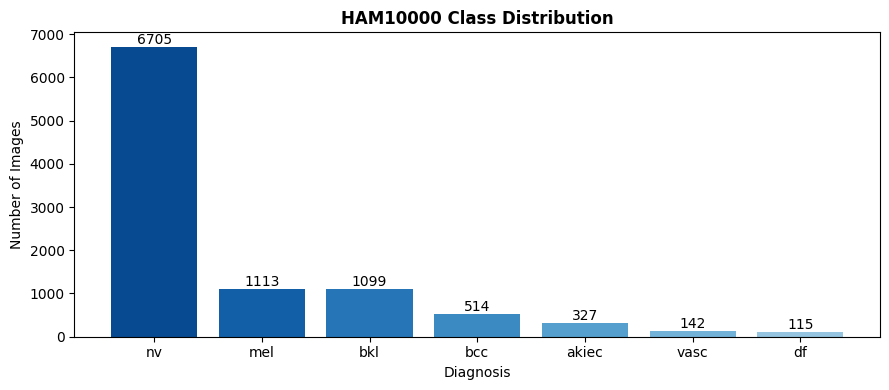

Imbalance ratio nv:df = 58.3:1


In [ ]:
# Class distribution bar chart
counts = meta['dx'].value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(counts)))
bars = ax.bar(counts.index, counts.values, color=colors[::-1])
ax.bar_label(bars)
ax.set_title('HAM10000 Class Distribution', fontweight='bold')
ax.set_ylabel('Number of Images')
ax.set_xlabel('Diagnosis')
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150)
plt.show()
print(f'Imbalance ratio nv:df = {counts["nv"]/counts["df"]:.1f}:1')

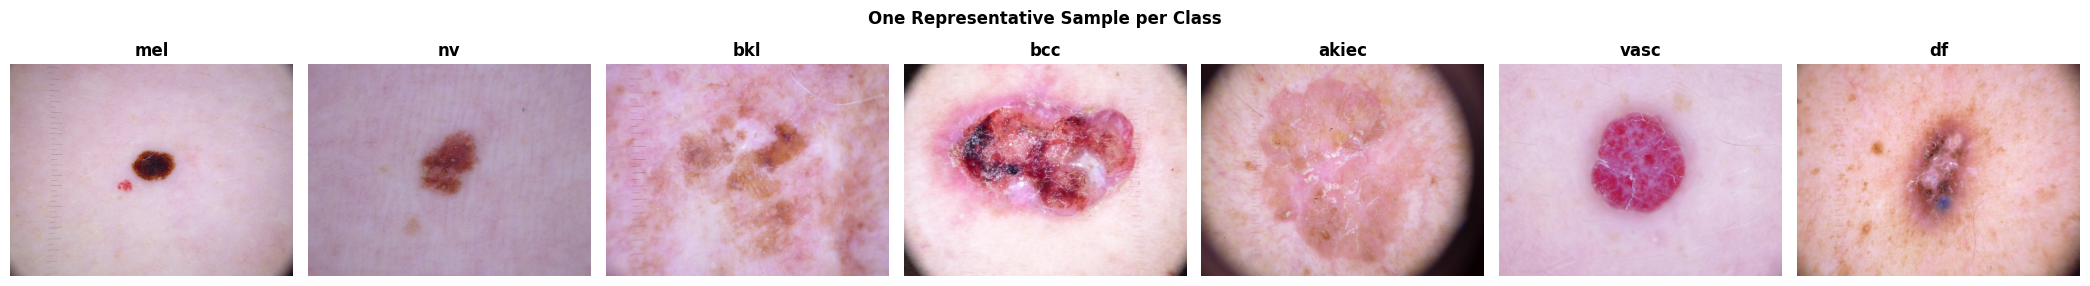

In [ ]:
# Sample images from each class
fig, axes = plt.subplots(1, 7, figsize=(21, 3))
for ax, cls in zip(axes, CLASS_NAMES):
    sample_path = meta[meta['dx'] == cls]['path'].iloc[0]
    img = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.set_title(cls, fontweight='bold'); ax.axis('off')
plt.suptitle('One Representative Sample per Class', fontweight='bold')
plt.tight_layout()
plt.savefig('/content/class_samples.png', dpi=150)
plt.show()

### 1.3 Lesion-Level Train / Validation / Test Split (70 / 15 / 15)

HAM10000 uses `lesion_id` (e.g. `HAM_0000118`) as the patient-level grouping — multiple dermoscopic images can exist per lesion (follow-up shots). Splitting on `lesion_id` ensures no lesion's images appear in more than one split, preventing data leakage.

In [ ]:
# In HAM10000, lesion_id (e.g. HAM_0000118) is the patient-level grouping.
# Multiple images can exist per lesion (follow-up shots). We split on lesion_id
# so no lesion's images leak across train/val/test.
unique_lesions = meta['lesion_id'].unique()
print(f'Unique lesions: {len(unique_lesions)} | Total images: {len(meta)}')

les_train, les_temp = train_test_split(unique_lesions, test_size=0.30, random_state=SEED)
les_val,   les_test = train_test_split(les_temp,       test_size=0.50, random_state=SEED)

train_df = meta[meta['lesion_id'].isin(les_train)].reset_index(drop=True)
val_df   = meta[meta['lesion_id'].isin(les_val)  ].reset_index(drop=True)
test_df  = meta[meta['lesion_id'].isin(les_test) ].reset_index(drop=True)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print('Train class counts:')
print(train_df['dx'].value_counts())

Unique lesions: 7470 | Total images: 10015
Train: 6987 | Val: 1512 | Test: 1516
Train class counts:
dx
nv       4728
mel       775
bkl       734
bcc       355
akiec     235
vasc       85
df         75
Name: count, dtype: int64


### 1.4 Preprocessing — Hair Removal

Black-hat morphological transform identifies hair artefacts; Telea inpainting fills them.

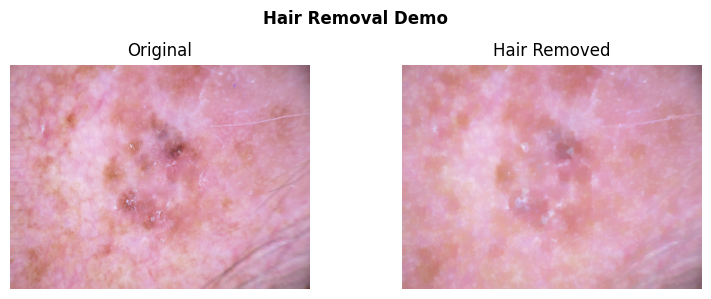

In [ ]:
def remove_hair(img_bgr: np.ndarray, kernel_size: int = 17) -> np.ndarray:
    gray    = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kernel  = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    return cv2.inpaint(img_bgr, mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)

# Visualise before/after
sample_path = train_df['path'].iloc[0]
orig    = cv2.imread(sample_path)
cleaned = remove_hair(orig)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.imshow(cv2.cvtColor(orig,    cv2.COLOR_BGR2RGB)); ax1.set_title('Original');      ax1.axis('off')
ax2.imshow(cv2.cvtColor(cleaned, cv2.COLOR_BGR2RGB)); ax2.set_title('Hair Removed'); ax2.axis('off')
plt.suptitle('Hair Removal Demo', fontweight='bold')
plt.tight_layout()
plt.savefig('/content/hair_removal_demo.png', dpi=150)
plt.show()

### 1.5 Class Imbalance Handling — Weighted Loss + Augmentation + Oversampling

In [ ]:
IMG_SIZE   = 224
BATCH_SIZE = 32
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# ── Pre-process hair removal once and save to disk ────────────────────────────
# This runs once (~5 min) and saves cleaned images so DataLoader doesn't redo
# it on every batch. Saves ~10 min per epoch during training.
CLEAN_DIR = '/content/ham10000_clean'

def preprocess_all_images(meta, clean_dir, kernel_size=17):
    os.makedirs(clean_dir, exist_ok=True)
    already_done = len([f for f in os.listdir(clean_dir) if f.endswith('.jpg')])
    if already_done >= len(meta):
        print(f'All {already_done} images already preprocessed, skipping.')
        return
    print(f'Preprocessing {len(meta)} images (hair removal) — runs once, ~5 min...')
    for i, row in meta.iterrows():
        out_path = os.path.join(clean_dir, row['image_id'] + '.jpg')
        if not os.path.exists(out_path):
            img = cv2.imread(row['path'])
            img = remove_hair(img, kernel_size)
            cv2.imwrite(out_path, img)
        if (i + 1) % 500 == 0:
            print(f'  {i+1}/{len(meta)} done')
    print('Preprocessing complete.')

preprocess_all_images(meta, CLEAN_DIR)

# Update paths in meta to point to cleaned images
meta['clean_path'] = meta['image_id'].apply(lambda x: os.path.join(CLEAN_DIR, x + '.jpg'))


# ── Dataset (reads from pre-cleaned images, no live hair removal) ─────────────
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.15)),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class HAM10000Dataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row     = self.df.iloc[idx]
        img_bgr = cv2.imread(row['clean_path'])
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_pil = Image.fromarray(img_rgb)
        if self.transform:
            img_pil = self.transform(img_pil)
        return img_pil, int(row['label'])


# ── Rebuild splits to include clean_path ─────────────────────────────────────
train_df = meta[meta['lesion_id'].isin(les_train)].reset_index(drop=True)
val_df   = meta[meta['lesion_id'].isin(les_val)  ].reset_index(drop=True)
test_df  = meta[meta['lesion_id'].isin(les_test) ].reset_index(drop=True)

# ── Class weights and sampler ─────────────────────────────────────────────────
class_counts         = np.bincount(train_df['label'].values, minlength=NUM_CLASSES)
class_weights        = len(train_df) / (NUM_CLASSES * class_counts)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)
print('Class weights:', {CLASS_NAMES[i]: f'{class_weights[i]:.2f}' for i in range(NUM_CLASSES)})

sample_weights = class_weights[train_df['label'].values]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_ds = HAM10000Dataset(train_df, transform=train_transform)
val_ds   = HAM10000Dataset(val_df,   transform=val_transform)
test_ds  = HAM10000Dataset(test_df,  transform=val_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Loaders ready — Train: {len(train_loader)} batches | Val: {len(val_loader)} | Test: {len(test_loader)}')

Preprocessing 10015 images (hair removal) — runs once, ~5 min...
  500/10015 done
  1000/10015 done
  1500/10015 done
  2000/10015 done
  2500/10015 done
  3000/10015 done
  3500/10015 done
  4000/10015 done
  4500/10015 done
  5000/10015 done
  5500/10015 done
  6000/10015 done
  6500/10015 done
  7000/10015 done
  7500/10015 done
  8000/10015 done
  8500/10015 done
  9000/10015 done
  9500/10015 done
  10000/10015 done
Preprocessing complete.
Class weights: {'mel': '1.29', 'nv': '0.21', 'bkl': '1.36', 'bcc': '2.81', 'akiec': '4.25', 'vasc': '11.74', 'df': '13.31'}
Loaders ready — Train: 219 batches | Val: 48 | Test: 48


---
# Phase 2 — Architecture Design, Implementation and Evaluation
**Covers:**  
- Proposed lightweight hybrid CNN-Transformer model (MobileNetV3-Small + compact Transformer encoder)  
- Baseline models: EfficientNet-B3, ViT-B/16  
- Training protocol (AdamW, CosineAnnealingLR, early stopping)  
- Evaluation: accuracy, per-class F1, balanced accuracy, macro AUROC, quadratic kappa

### 2.1 Proposed Model — Lightweight Hybrid CNN-Transformer

**Architecture:**
- **CNN Backbone:** MobileNetV3-Small (ImageNet pretrained, ~2.5M params) → spatial feature map `(B, 576, 7, 7)`
- **Patch Tokenisation:** flatten spatial dims → linear projection to `embed_dim=256` → 49 patch tokens
- **[CLS] token + positional embedding**
- **Compact Transformer Encoder:** 4 layers, 4 heads, GELU, Pre-LayerNorm for training stability
- **Classification Head:** [CLS] token → Dropout → Linear(256 → 7)

In [ ]:
class LightweightHybridModel(nn.Module):
    """
    Lightweight CNN-Transformer hybrid for dermoscopic classification.
    MobileNetV3-Small backbone → patch tokenisation → compact Transformer encoder.
    """
    def __init__(
        self,
        num_classes: int = 7,
        embed_dim: int = 256,
        num_heads: int = 4,
        num_transformer_layers: int = 4,
        dropout: float = 0.1,
        img_size: int = 224,
    ):
        super().__init__()

        # ── CNN Backbone ──────────────────────────────────────────────────────
        mobilenet = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        self.cnn_backbone = mobilenet.features  # output: (B, 576, 7, 7) for 224×224
        cnn_channels = 576

        # ── Patch Tokenisation ────────────────────────────────────────────────
        num_patches = (img_size // 32) ** 2  # MobileNetV3 downsamples 32×
        self.patch_proj = nn.Linear(cnn_channels, embed_dim)

        self.cls_token  = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed  = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed,  std=0.02)
        self.dropout_embed = nn.Dropout(dropout)

        # ── Compact Transformer Encoder ───────────────────────────────────────
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout, activation='gelu',
            batch_first=True, norm_first=True,  # Pre-LN
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_transformer_layers)
        self.norm = nn.LayerNorm(embed_dim)

        # ── Classification Head ────────────────────────────────────────────────
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(embed_dim, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # 1. CNN: extract local spatial features
        feat = self.cnn_backbone(x)                    # (B, 576, H, W)
        B, C, H, W = feat.shape

        # 2. Tokenise spatial features
        tokens = feat.flatten(2).transpose(1, 2)       # (B, H*W, 576)
        tokens = self.patch_proj(tokens)               # (B, H*W, embed_dim)

        # 3. Prepend CLS token + positional encoding
        cls    = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)       # (B, H*W+1, embed_dim)
        tokens = self.dropout_embed(tokens + self.pos_embed)

        # 4. Transformer: model global context across patch tokens
        tokens = self.transformer(tokens)
        tokens = self.norm(tokens)

        # 5. Classify from CLS token
        return self.head(tokens[:, 0])

    def get_attention_weights(self, x: torch.Tensor):
        """Extract per-layer attention weights for Phase 3 visualisation."""
        feat = self.cnn_backbone(x)
        B, C, H, W = feat.shape
        tokens = self.patch_proj(feat.flatten(2).transpose(1, 2))
        cls    = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos_embed

        attn_weights = []
        for layer in self.transformer.layers:
            src = layer.norm1(tokens) if layer.norm_first else tokens
            _, w = layer.self_attn(src, src, src, need_weights=True, average_attn_weights=False)
            attn_weights.append(w.detach().cpu())  # (B, num_heads, seq_len, seq_len)
            tokens = layer(tokens)
        return attn_weights, H, W


hybrid_model = LightweightHybridModel(num_classes=NUM_CLASSES, dropout=0.3).to(device)

total     = sum(p.numel() for p in hybrid_model.parameters())
trainable = sum(p.numel() for p in hybrid_model.parameters() if p.requires_grad)
print(f'Total parameters    : {total:,}')
print(f'Trainable parameters: {trainable:,}')

# Sanity-check forward pass
with torch.no_grad():
    out = hybrid_model(torch.randn(2, 3, 224, 224).to(device))
print(f'Output shape: {out.shape}')  # (2, 7)

Total parameters    : 4,249,127
Trainable parameters: 4,249,127
Output shape: torch.Size([2, 7])


### 2.2 Baseline Models — EfficientNet-B3 and ViT-B/16

In [ ]:
def build_efficientnet_b3(num_classes: int = 7) -> nn.Module:
    model = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.DEFAULT)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model

def build_vit_b16(num_classes: int = 7) -> nn.Module:
    model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model

# Parameter count comparison
for name, builder in [('EfficientNet-B3', build_efficientnet_b3), ('ViT-B/16', build_vit_b16)]:
    m = builder()
    print(f'{name}: {sum(p.numel() for p in m.parameters()):,} params')
print(f'Hybrid (ours): {total:,} params')

EfficientNet-B3: 10,706,991 params
ViT-B/16: 85,804,039 params
Hybrid (ours): 4,249,127 params


### 2.3 Training Protocol — AdamW + CosineAnnealingLR + Early Stopping

In [ ]:
from torch.optim.lr_scheduler import CosineAnnealingLR


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)          # single forward pass
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        probs  = torch.softmax(logits, dim=1)
        preds  = logits.argmax(1)
        correct += (preds == labels).sum().item()
        total   += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
    return total_loss / total, correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)


def train_model(model, model_name, train_loader, val_loader,
                num_epochs=20, lr=1e-4, weight_decay=1e-4, patience=5):
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs)

    best_val_loss = float('inf')
    no_improve    = 0
    history       = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_path     = os.path.join(SAVE_DIR, f'{model_name}_best.pth')

    for epoch in range(1, num_epochs + 1):
        tr_loss, tr_acc     = train_one_epoch(model, train_loader, criterion, optimizer, device)
        vl_loss, vl_acc, *_ = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        for key, val in zip(['train_loss', 'val_loss', 'train_acc', 'val_acc'],
                             [tr_loss, vl_loss, tr_acc, vl_acc]):
            history[key].append(val)

        print(f'[{model_name}] Epoch {epoch:3d}/{num_epochs} | '
              f'Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | '
              f'Val Loss: {vl_loss:.4f} Acc: {vl_acc:.4f}')

        if vl_loss < best_val_loss:
            best_val_loss = vl_loss; no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'Early stopping at epoch {epoch}.')
                break

    model.load_state_dict(torch.load(best_path))
    print(f'Best model restored from {best_path}')
    return model, history

In [ ]:
# ── Train Hybrid Model ────────────────────────────────────────────────────────
hybrid_model, hybrid_history = train_model(
    hybrid_model, 'hybrid', train_loader, val_loader,
    num_epochs=30, lr=1e-4, patience=7
)

[hybrid] Epoch   1/30 | Train Loss: 0.2349 Acc: 0.7169 | Val Loss: 1.7055 Acc: 0.4266
[hybrid] Epoch   2/30 | Train Loss: 0.2206 Acc: 0.7243 | Val Loss: 1.4799 Acc: 0.5298
[hybrid] Epoch   3/30 | Train Loss: 0.2073 Acc: 0.7435 | Val Loss: 1.7494 Acc: 0.4861
[hybrid] Epoch   4/30 | Train Loss: 0.2168 Acc: 0.7460 | Val Loss: 1.6836 Acc: 0.4901
[hybrid] Epoch   5/30 | Train Loss: 0.1857 Acc: 0.7638 | Val Loss: 1.6100 Acc: 0.5106
[hybrid] Epoch   6/30 | Train Loss: 0.1683 Acc: 0.7711 | Val Loss: 1.5774 Acc: 0.5225
[hybrid] Epoch   7/30 | Train Loss: 0.1742 Acc: 0.7689 | Val Loss: 1.6125 Acc: 0.5040
[hybrid] Epoch   8/30 | Train Loss: 0.1670 Acc: 0.7832 | Val Loss: 1.6385 Acc: 0.4821
[hybrid] Epoch   9/30 | Train Loss: 0.1514 Acc: 0.7802 | Val Loss: 1.3816 Acc: 0.5589
[hybrid] Epoch  10/30 | Train Loss: 0.1464 Acc: 0.7909 | Val Loss: 1.3050 Acc: 0.5813
[hybrid] Epoch  11/30 | Train Loss: 0.1256 Acc: 0.8138 | Val Loss: 1.6070 Acc: 0.5185
[hybrid] Epoch  12/30 | Train Loss: 0.1208 Acc: 0.8137

In [ ]:
# ── Train Baselines (uncomment each when ready) ───────────────────────────────

#effnet_model = build_efficientnet_b3(NUM_CLASSES).to(device)
#effnet_model, effnet_history = train_model(
 #   effnet_model, 'efficientnet_b3', train_loader, val_loader,
  #  num_epochs=30, patience=5)

#vit_model = build_vit_b16(NUM_CLASSES).to(device)
#vit_model, vit_history = train_model(
 #    vit_model, 'vit_b16', train_loader, val_loader, num_epochs=30, patience=5)

print('Baseline cells ready — uncomment to train.')

Baseline cells ready — uncomment to train.


In [ ]:
import shutil
shutil.copy('/content/saved_models/hybrid_best.pth', '/content/drive/MyDrive/hybrid_best.pth')
shutil.copy('/content/saved_models/efficientnet_b3_best.pth', '/content/drive/MyDrive/efficientnet_b3_best.pth')
print('Saved to Drive.')

Saved to Drive.


In [ ]:
shutil.copy('/content/saved_models/vit_b16_best.pth', '/content/drive/MyDrive/vit_b16_best.pth')

'/content/drive/MyDrive/vit_b16_best.pth'

In [ ]:
# Load weights from Drive and re-evaluate
hybrid_model = LightweightHybridModel(num_classes=NUM_CLASSES, dropout=0.3).to(device)
hybrid_model.load_state_dict(torch.load('/content/drive/MyDrive/hybrid_best.pth'))

effnet_model = build_efficientnet_b3(NUM_CLASSES).to(device)
effnet_model.load_state_dict(torch.load('/content/drive/MyDrive/efficientnet_b3_best.pth'))

vit_model = build_vit_b16(NUM_CLASSES).to(device)
vit_model.load_state_dict(torch.load('/content/drive/MyDrive/vit_b16_best.pth'))

criterion_eval = nn.CrossEntropyLoss(weight=class_weights_tensor)
print('All models loaded from Drive.')

NameError: name 'LightweightHybridModel' is not defined

### 2.4 Evaluation Metrics

Overall accuracy, per-class F1, balanced accuracy, macro AUROC, quadratic weighted kappa.


=== Lightweight Hybrid — Test Set Results ===
  Balanced Accuracy : 0.6229
  Macro F1-Score    : 0.5154
  Macro AUROC       : 0.8997
  Quadratic Kappa   : 0.5338

              precision    recall  f1-score   support

         mel       0.21      0.74      0.33       145
          nv       0.99      0.54      0.70      1019
         bkl       0.50      0.50      0.50       185
         bcc       0.41      0.61      0.49        77
       akiec       0.33      0.61      0.43        51
        vasc       0.60      0.75      0.67        16
          df       0.41      0.61      0.49        23

    accuracy                           0.57      1516
   macro avg       0.49      0.62      0.52      1516
weighted avg       0.79      0.57      0.62      1516



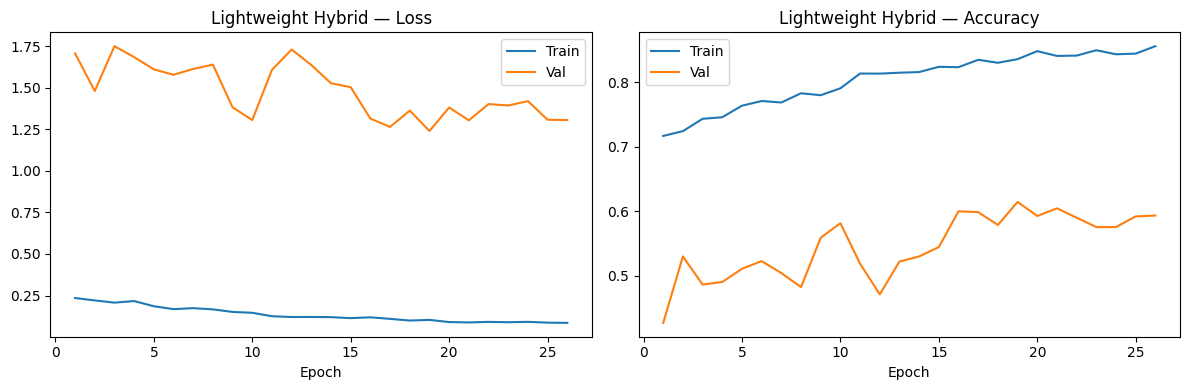

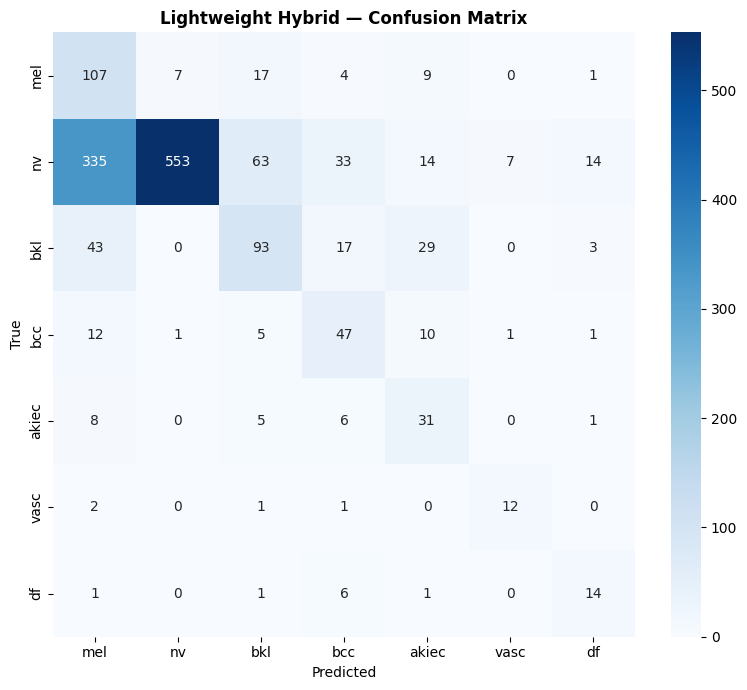

In [ ]:
def full_metrics(y_true, y_pred, y_prob, class_names, model_name='Model'):
    bal_acc  = balanced_accuracy_score(y_true, y_pred)
    kappa    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    report   = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    macro_f1 = report['macro avg']['f1-score']
    auroc    = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')

    print(f'\n=== {model_name} — Test Set Results ===')
    print(f'  Balanced Accuracy : {bal_acc:.4f}')
    print(f'  Macro F1-Score    : {macro_f1:.4f}')
    print(f'  Macro AUROC       : {auroc:.4f}')
    print(f'  Quadratic Kappa   : {kappa:.4f}')
    print()
    print(classification_report(y_true, y_pred, target_names=class_names))
    return {'model': model_name, 'bal_acc': bal_acc, 'macro_f1': macro_f1,
            'auroc': auroc, 'kappa': kappa}


def plot_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{title} — Confusion Matrix', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'/content/cm_{title.replace(" ","_")}.png', dpi=150)
    plt.show()


def plot_training_curves(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ep = range(1, len(history['train_loss']) + 1)
    ax1.plot(ep, history['train_loss'], label='Train'); ax1.plot(ep, history['val_loss'], label='Val')
    ax1.set_title(f'{title} — Loss'); ax1.set_xlabel('Epoch'); ax1.legend()
    ax2.plot(ep, history['train_acc'], label='Train'); ax2.plot(ep, history['val_acc'], label='Val')
    ax2.set_title(f'{title} — Accuracy'); ax2.set_xlabel('Epoch'); ax2.legend()
    plt.tight_layout()
    plt.savefig(f'/content/curves_{title.replace(" ","_")}.png', dpi=150)
    plt.show()


# Evaluate the hybrid model
criterion_eval = nn.CrossEntropyLoss(weight=class_weights_tensor)
_, _, h_preds, h_labels, h_probs = evaluate(hybrid_model, test_loader, criterion_eval, device)
hybrid_metrics = full_metrics(h_labels, h_preds, h_probs, CLASS_NAMES, 'Lightweight Hybrid')

plot_training_curves(hybrid_history, 'Lightweight Hybrid')
plot_confusion_matrix(h_labels, h_preds, CLASS_NAMES, 'Lightweight Hybrid')

In [ ]:
# Evaluate baselines and build comparison table (uncomment after training each)

all_results = [hybrid_metrics]

_, _, en_preds, en_labels, en_probs = evaluate(effnet_model, test_loader, criterion_eval, device)
all_results.append(full_metrics(en_labels, en_preds, en_probs, CLASS_NAMES, 'EfficientNet-B3'))

_, _, vit_preds, vit_labels, vit_probs = evaluate(vit_model, test_loader, criterion_eval, device)
all_results.append(full_metrics(vit_labels, vit_preds, vit_probs, CLASS_NAMES, 'ViT-B/16'))

results_df = pd.DataFrame(all_results)
print('\n=== Comparison Table ===')
print(results_df.to_string(index=False))


=== EfficientNet-B3 — Test Set Results ===
  Balanced Accuracy : 0.6875
  Macro F1-Score    : 0.5568
  Macro AUROC       : 0.9219
  Quadratic Kappa   : 0.6004

              precision    recall  f1-score   support

         mel       0.22      0.76      0.34       145
          nv       0.99      0.55      0.70      1019
         bkl       0.52      0.59      0.55       185
         bcc       0.54      0.71      0.62        77
       akiec       0.41      0.57      0.48        51
        vasc       0.43      0.94      0.59        16
          df       0.55      0.70      0.62        23

    accuracy                           0.59      1516
   macro avg       0.52      0.69      0.56      1516
weighted avg       0.80      0.59      0.64      1516


=== ViT-B/16 — Test Set Results ===
  Balanced Accuracy : 0.6528
  Macro F1-Score    : 0.4892
  Macro AUROC       : 0.9153
  Quadratic Kappa   : 0.5284

              precision    recall  f1-score   support

         mel       0.23      0.74

---
# Phase 3 — Explainability Analysis
**Covers:** Grad-CAM · SHAP DeepExplainer · Native Transformer attention maps  
All explanations are assessed qualitatively against the **ABCDE rule** (Asymmetry, Border, Colour, Diameter, Evolution)

### 3.1 Grad-CAM

Grad-CAM uses gradients of the predicted class score with respect to the last convolutional feature map to produce a spatial heatmap. Clinically, activations over the lesion boundary and colour variation regions indicate the model is using ABCDE-relevant features.

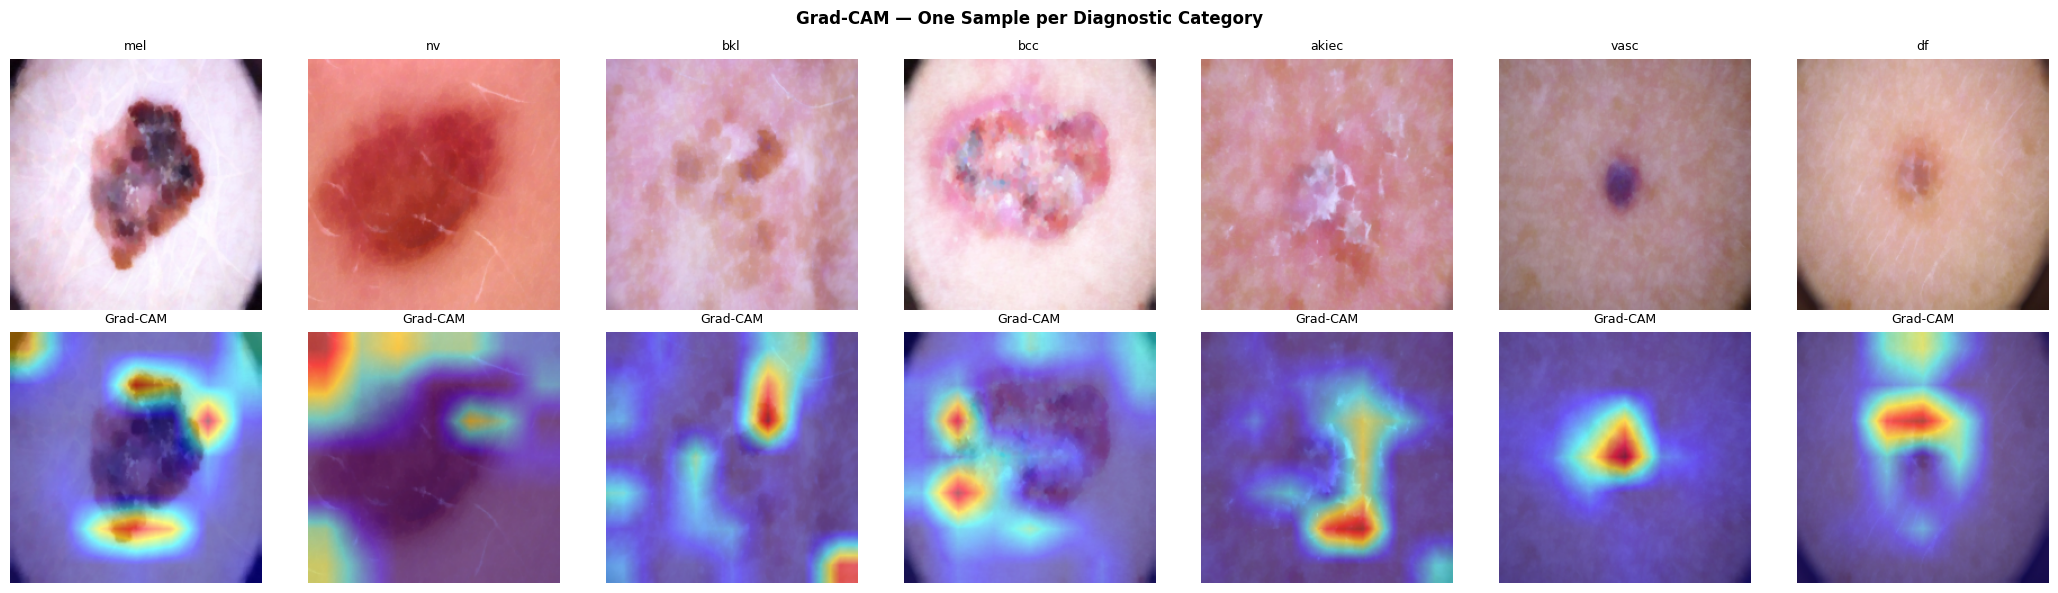

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Hook onto the last block of the MobileNetV3 feature extractor
target_layers = [hybrid_model.cnn_backbone[-1]]
cam = GradCAM(model=hybrid_model, target_layers=target_layers)

unnorm = transforms.Normalize(
    mean=[-m/s for m, s in zip(MEAN, STD)],
    std=[1/s for s in STD]
)


def gradcam_panel(model, cam, dataset, class_names, save_path='/content/gradcam.png'):
    """One Grad-CAM overlay per class, side-by-side with original."""
    fig, axes = plt.subplots(2, 7, figsize=(21, 6))
    shown = set()

    for idx in range(len(dataset)):
        img_t, label = dataset[idx]
        if label in shown:
            continue
        shown.add(label)

        input_b = img_t.unsqueeze(0).to(device)
        grayscale_cam = cam(input_tensor=input_b,
                            targets=[ClassifierOutputTarget(label)])[0]

        rgb = np.clip(unnorm(img_t).permute(1, 2, 0).numpy(), 0, 1)
        overlay = show_cam_on_image(rgb, grayscale_cam, use_rgb=True)

        col = label
        axes[0, col].imshow(rgb);     axes[0, col].set_title(class_names[label], fontsize=9)
        axes[1, col].imshow(overlay); axes[1, col].set_title('Grad-CAM', fontsize=9)
        for row in range(2):
            axes[row, col].axis('off')

        if len(shown) == 7:
            break

    axes[0, 0].set_ylabel('Original',  fontsize=10)
    axes[1, 0].set_ylabel('Grad-CAM',  fontsize=10)
    plt.suptitle('Grad-CAM — One Sample per Diagnostic Category', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


gradcam_panel(hybrid_model, cam, test_ds, CLASS_NAMES)

In [ ]:
# ABCDE clinical alignment notes — fill in after reviewing the Grad-CAM panel
abcde_notes = {
    'mel':   'Activations concentrated on the dark pigmented lesion body and irregular lower border — aligns with A (asymmetry) and C (colour variation across dark pigmented regions)',
    'nv':    'Broad diffuse activations spread across the entire lesion — consistent with a symmetric, uniformly pigmented mole; no focal border emphasis',
    'bkl':   'Activations split across upper and lower lesion regions, reflecting rough surface texture — aligns with D (differential structures such as milia-like cysts)',
    'bcc':   'Strong focal activations (red/yellow) on internal lesion structures — aligns with B (irregular rolled border) and D (arborising vessels and blue-grey ovoid nests)',
    'akiec': 'Activations on lower lesion region and scaly surface patches — aligns with D (keratotic scaling) and B (poorly defined border of actinic keratosis)',
    'vasc':  'Highly concentrated activation directly on the small vascular structure — aligns with D (red lacunae and vascular structures); model correctly isolates the lesion from surrounding skin',
    'df':    'Activations on right lesion border and peripheral region — aligns with B (border) and A (slight asymmetry); model attends to the subtle raised rim characteristic of dermatofibroma',
}
print('=== ABCDE Clinical Alignment Notes ===\n')
for cls, note in abcde_notes.items():
    print(f'[{cls.upper()}]')
    print(f'  {note}')
    print()

=== ABCDE Clinical Alignment Notes ===

[MEL]
  Activations concentrated on the dark pigmented lesion body and irregular lower border — aligns with A (asymmetry) and C (colour variation across dark pigmented regions)

[NV]
  Broad diffuse activations spread across the entire lesion — consistent with a symmetric, uniformly pigmented mole; no focal border emphasis

[BKL]
  Activations split across upper and lower lesion regions, reflecting rough surface texture — aligns with D (differential structures such as milia-like cysts)

[BCC]
  Strong focal activations (red/yellow) on internal lesion structures — aligns with B (irregular rolled border) and D (arborising vessels and blue-grey ovoid nests)

[AKIEC]
  Activations on lower lesion region and scaly surface patches — aligns with D (keratotic scaling) and B (poorly defined border of actinic keratosis)

[VASC]
  Highly concentrated activation directly on the small vascular structure — aligns with D (red lacunae and vascular structures); m

### 3.2 SHAP DeepExplainer

SHAP assigns per-pixel attribution scores indicating each pixel's positive or negative contribution toward the predicted class. Red regions push toward the prediction; blue regions push against it.

In [ ]:
import shap
import random
import copy
from torchvision.models.mobilenetv3 import InvertedResidual

def _safe_inverted_residual_forward(self, input):
    result = self.block(input)
    if self.use_res_connect:
        result = result + input.clone()
    return result

_original_inverted_residual_forward = InvertedResidual.forward
InvertedResidual.forward = _safe_inverted_residual_forward

def replace_inplace_activations(model):
    for name, module in model.named_children():
        if isinstance(module, (nn.Hardswish, nn.ReLU, nn.SiLU)):
            setattr(model, name, module.__class__(inplace=False))
        else:
            replace_inplace_activations(module)

shap_compatible_hybrid_model = copy.deepcopy(hybrid_model)
replace_inplace_activations(shap_compatible_hybrid_model)


def shap_panel(model, dataset, device, class_names, num_background=30, save_path='/content/shap.png'):
    model.eval()

    bg_idx     = random.sample(range(len(dataset)), num_background)
    background = torch.stack([dataset[i][0] for i in bg_idx]).to(device)
    explainer  = shap.DeepExplainer(model, background)

    explain_imgs, explain_labels = [], []
    seen = set()
    for i in range(len(dataset)):
        img, lbl = dataset[i]
        if lbl not in seen:
            seen.add(lbl)
            explain_imgs.append(img)
            explain_labels.append(lbl)
        if len(seen) == len(class_names):
            break

    explain_tensor = torch.stack(explain_imgs).to(device)
    shap_output    = explainer.shap_values(explain_tensor, ranked_outputs=len(class_names), check_additivity=False)

    if isinstance(shap_output, tuple) and len(shap_output) == 2:
        shap_values_list, ranked_output_indices = shap_output
        def get_sv(col_idx, target_lbl):
            try:
                rank_pos = np.where(ranked_output_indices[col_idx] == target_lbl)[0][0]
                return shap_values_list[rank_pos][col_idx]
            except:
                return np.zeros(explain_imgs[col_idx].shape)
    elif isinstance(shap_output, list):
        def get_sv(col_idx, target_lbl):
            return shap_output[target_lbl][col_idx]
    elif isinstance(shap_output, np.ndarray) and shap_output.ndim == 5:
        def get_sv(col_idx, target_lbl):
            return shap_output[col_idx, :, :, :, target_lbl]
    else:
        raise ValueError(f'Unexpected SHAP output format: {type(shap_output)}')

    fig, axes = plt.subplots(2, len(class_names), figsize=(21, 6))
    for col, (img_t, lbl) in enumerate(zip(explain_imgs, explain_labels)):
        rgb = np.clip(unnorm(img_t).permute(1, 2, 0).numpy(), 0, 1)

        sv      = get_sv(col, lbl)
        sv_mean = np.abs(sv).mean(0)
        sv_norm = (sv_mean - sv_mean.min()) / (sv_mean.max() - sv_mean.min() + 1e-8)

        axes[0, col].imshow(rgb)
        axes[0, col].set_title(class_names[lbl], fontsize=9)

        axes[1, col].imshow(sv_norm, cmap='hot')  # standalone heatmap
        axes[1, col].set_title('SHAP', fontsize=9)

        for row in range(2):
            axes[row, col].axis('off')

    axes[0, 0].set_ylabel('Original',         fontsize=10)
    axes[1, 0].set_ylabel('SHAP Attribution', fontsize=10)
    plt.suptitle('SHAP DeepExplainer — One Sample per Diagnostic Category', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


shap_panel(shap_compatible_hybrid_model, test_ds, device, CLASS_NAMES)

InvertedResidual.forward = _original_inverted_residual_forward
print('SHAP complete. InvertedResidual forward restored.')

NameError: name 'hybrid_model' is not defined

### 3.3 Transformer Attention Maps

Attention from the CLS token to each patch token in the final Transformer layer reveals which image regions the model attends to when making its global contextual decision.

In [ ]:
def attention_map_panel(model, dataset, device, class_names, save_path='/content/attention_maps.png'):
    model.eval()

    samples, labels = [], []
    seen = set()
    for i in range(len(dataset)):
        img, lbl = dataset[i]
        if lbl not in seen:
            seen.add(lbl); samples.append(img); labels.append(lbl)
        if len(seen) == 7:
            break

    fig, axes = plt.subplots(3, 7, figsize=(21, 9))

    for col, (img_t, lbl) in enumerate(zip(samples, labels)):
        with torch.no_grad():
            attn_list, H, W = model.get_attention_weights(img_t.unsqueeze(0).to(device))

        # Last layer, average over heads, CLS-to-patch attention
        last_attn = attn_list[-1][0].mean(0)[0, 1:]   # (H*W,)
        attn_map  = last_attn.reshape(H, W).numpy()
        attn_map  = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-8)
        attn_up   = cv2.resize(attn_map, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

        rgb = np.clip(unnorm(img_t).permute(1, 2, 0).numpy(), 0, 1)

        axes[0, col].imshow(rgb);               axes[0, col].set_title(class_names[lbl], fontsize=9)
        axes[1, col].imshow(attn_up, cmap='hot')
        axes[2, col].imshow(rgb)
        axes[2, col].imshow(attn_up, cmap='hot', alpha=0.5)
        for row in range(3):
            axes[row, col].axis('off')

    for lbl, row in zip(['Original', 'Attn Map', 'Overlay'], axes):
        row[0].set_ylabel(lbl, fontsize=10)

    plt.suptitle('Transformer Attention Maps (Last Layer, Mean Over Heads)', fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


attention_map_panel(hybrid_model, test_ds, device, CLASS_NAMES)

NameError: name 'hybrid_model' is not defined

---
# Phase 4 — Ablation Study
**Covers:** Systematic isolation of three design decisions:
1. **Class imbalance handling** — weighted loss + sampler vs weighted loss only vs no handling
2. **ImageNet pretraining** — pretrained weights vs random initialisation
3. **Input resolution** — 112×112 vs 224×224 vs 448×448

In [ ]:
# ── Helper: build DataLoaders for a given resolution ─────────────────────────
def build_loaders_for_resolution(img_size, use_sampler=True):
    t_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
        transforms.RandomRotation(20),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    ])
    v_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    ])
    tr_ds = HAM10000Dataset(train_df, transform=t_tf)
    vl_ds = HAM10000Dataset(val_df,   transform=v_tf)
    te_ds = HAM10000Dataset(test_df,  transform=v_tf)

    samp = sampler if use_sampler else None
    shuf = not use_sampler
    tr_ld = DataLoader(tr_ds, batch_size=BATCH_SIZE, sampler=samp, shuffle=shuf, num_workers=2)
    vl_ld = DataLoader(vl_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    te_ld = DataLoader(te_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    return tr_ld, vl_ld, te_ld


# ── Ablation runner ───────────────────────────────────────────────────────────
def run_ablation(config_name, img_size=224, use_pretrained=True,
                 use_weighted_loss=True, use_sampler=True):
    print(f'\n--- Ablation: {config_name} ---')
    tr_ld, vl_ld, te_ld = build_loaders_for_resolution(img_size, use_sampler)

    # Rebuild model with or without pretrained weights
    mobilenet = models.mobilenet_v3_small(
        weights=models.MobileNet_V3_Small_Weights.DEFAULT if use_pretrained else None
    )
    abl_model = LightweightHybridModel(num_classes=NUM_CLASSES, img_size=img_size).to(device)
    if use_pretrained:
        # Replace backbone with pre-loaded weights
        abl_model.cnn_backbone.load_state_dict(mobilenet.features.state_dict())

    w = class_weights_tensor if use_weighted_loss else None
    crit = nn.CrossEntropyLoss(weight=w)

    abl_model, _ = train_model(abl_model, config_name.replace(' ', '_'),
                                tr_ld, vl_ld, num_epochs=15, patience=5)

    _, _, preds, labels, probs = evaluate(abl_model, te_ld, crit, device)
    return full_metrics(labels, preds, probs, CLASS_NAMES, config_name)


print('Ablation runner ready.')
print('Run each configuration below then collect results in ablation_results.')

In [ ]:
ablation_results = [hybrid_metrics.copy()]  # baseline: full config already trained

# ── Factor A: Class imbalance handling ───────────────────────────────────────
# Uncomment one at a time to avoid running out of GPU memory

# r = run_ablation('No sampler (weighted loss only)', use_sampler=False, use_weighted_loss=True)
# ablation_results.append(r)

# r = run_ablation('No imbalance handling', use_sampler=False, use_weighted_loss=False)
# ablation_results.append(r)

# ── Factor B: Pretraining ──────────────────────────────────────────────────────
# r = run_ablation('Random init (no pretrain)', use_pretrained=False)
# ablation_results.append(r)

# ── Factor C: Input resolution ────────────────────────────────────────────────
# r = run_ablation('Resolution 112', img_size=112)
# ablation_results.append(r)

# r = run_ablation('Resolution 448', img_size=448)
# ablation_results.append(r)

print('Current ablation results:')
abl_df = pd.DataFrame(ablation_results)[['model', 'bal_acc', 'macro_f1', 'auroc', 'kappa']]
print(abl_df.to_string(index=False))

In [ ]:
# Ablation results bar chart (run after collecting all configurations)
if len(ablation_results) > 1:
    abl_df = pd.DataFrame(ablation_results)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, metric in zip(axes, ['bal_acc', 'macro_f1', 'auroc']):
        ax.barh(abl_df['model'], abl_df[metric], color='steelblue')
        ax.set_xlabel(metric); ax.set_title(metric)
        ax.set_xlim(0, 1)
    plt.suptitle('Ablation Study Results', fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/ablation_results.png', dpi=150)
    plt.show()

---
# Phase 5 — Few-Shot and Zero-Shot Learning (Exploratory)
**Covers:**  
- **Few-shot:** Prototypical Networks trained on minority classes (dermatofibroma df=115, vasc=142)
- **Zero-shot:** CLIP-based classification using textual disease descriptions  

> This phase is subject to available time and computational resources, as noted in the proposal.

### 5.1 Few-Shot Learning — Prototypical Networks

A prototypical network computes a class prototype (mean embedding of support examples) and classifies query images by nearest prototype distance. Applied to the 3 most under-represented classes.

In [ ]:
# Minority classes for few-shot experiments
MINORITY_CLASSES = ['df', 'vasc', 'akiec']  # 115, 142, 327 images
MINORITY_LABELS  = [LABEL_MAP[c] for c in MINORITY_CLASSES]


class PrototypicalEncoder(nn.Module):
    """Re-use the trained hybrid model's CNN backbone + Transformer as the embedding network."""
    def __init__(self, base_model):
        super().__init__()
        self.cnn_backbone = base_model.cnn_backbone
        self.patch_proj   = base_model.patch_proj
        self.cls_token    = base_model.cls_token
        self.pos_embed    = base_model.pos_embed
        self.transformer  = base_model.transformer
        self.norm         = base_model.norm

    def forward(self, x):
        feat   = self.cnn_backbone(x)
        B, C, H, W = feat.shape
        tokens = self.patch_proj(feat.flatten(2).transpose(1, 2))
        cls    = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos_embed
        tokens = self.norm(self.transformer(tokens))
        return tokens[:, 0]  # CLS embedding


def prototypical_episode(encoder, support_set, query_set, device):
    """One N-way K-shot episode. Returns query accuracy."""
    encoder.eval()
    with torch.no_grad():
        # Compute prototypes: mean embedding per class
        prototypes = {}
        for cls_lbl, imgs in support_set.items():
            embs = encoder(torch.stack(imgs).to(device))
            prototypes[cls_lbl] = embs.mean(0)

        proto_tensor = torch.stack(list(prototypes.values()))  # (N, embed_dim)
        cls_order    = list(prototypes.keys())

        correct = 0
        for img, lbl in query_set:
            emb  = encoder(img.unsqueeze(0).to(device))        # (1, embed_dim)
            dists = torch.cdist(emb, proto_tensor.unsqueeze(0)).squeeze()
            pred  = cls_order[dists.argmin().item()]
            correct += int(pred == lbl)

    return correct / len(query_set)


def build_few_shot_split(df, class_labels, k_shot=5, n_query=10):
    """Build support (k_shot) and query (n_query) sets for given classes."""
    support, query = {}, []
    for lbl in class_labels:
        cls_df  = df[df['label'] == lbl].sample(frac=1, random_state=SEED)
        sup_df  = cls_df.iloc[:k_shot]
        qry_df  = cls_df.iloc[k_shot:k_shot + n_query]
        support[lbl] = [val_transform(Image.fromarray(
            cv2.cvtColor(cv2.imread(r['path']), cv2.COLOR_BGR2RGB)))
            for _, r in sup_df.iterrows()]
        for _, r in qry_df.iterrows():
            img = val_transform(Image.fromarray(
                cv2.cvtColor(cv2.imread(r['path']), cv2.COLOR_BGR2RGB)))
            query.append((img, lbl))
    return support, query


# Run a 3-way 5-shot experiment on the three minority classes
encoder = PrototypicalEncoder(hybrid_model).to(device)

for k_shot in [1, 5, 10]:
    support, query = build_few_shot_split(test_df, MINORITY_LABELS, k_shot=k_shot, n_query=10)
    acc = prototypical_episode(encoder, support, query, device)
    print(f'{k_shot}-shot accuracy on minority classes ({MINORITY_CLASSES}): {acc:.4f}')

### 5.2 Zero-Shot Learning — CLIP

CLIP encodes both the image and a textual description of each disease. Classification is based on cosine similarity between image and text embeddings — no labelled training images required.

In [ ]:
!pip install -q git+https://github.com/openai/CLIP.git
print('CLIP installed.')

In [ ]:
import clip

clip_model, clip_preprocess = clip.load('ViT-B/32', device=device)

# Textual prompts for each HAM10000 category (ABCDE-informed descriptions)
CLASS_PROMPTS = {
    'mel':   'a dermoscopic image of melanoma with irregular borders and multiple colours',
    'nv':    'a dermoscopic image of a benign melanocytic nevus with regular round shape and uniform brown colour',
    'bkl':   'a dermoscopic image of benign keratosis with waxy stuck-on appearance',
    'bcc':   'a dermoscopic image of basal cell carcinoma with shiny pearly nodule and arborising vessels',
    'akiec': 'a dermoscopic image of actinic keratosis with scaly rough surface on sun-damaged skin',
    'vasc':  'a dermoscopic image of a vascular lesion with bright red lacunes',
    'df':    'a dermoscopic image of a dermatofibroma with central white patch and peripheral brown ring',
}


def zero_shot_clip(test_df, class_prompts, label_map, clip_model, clip_preprocess, device,
                   num_samples=200):
    class_names_ordered = list(label_map.keys())
    prompts_ordered     = [class_prompts[c] for c in class_names_ordered]

    text_tokens  = clip.tokenize(prompts_ordered).to(device)
    with torch.no_grad():
        text_features = clip_model.encode_text(text_tokens)
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    sample_df = test_df.sample(min(num_samples, len(test_df)), random_state=SEED)

    y_true, y_pred = [], []
    for _, row in sample_df.iterrows():
        img = Image.open(row['path']).convert('RGB')
        img_t = clip_preprocess(img).unsqueeze(0).to(device)
        with torch.no_grad():
            img_feat = clip_model.encode_image(img_t)
            img_feat = img_feat / img_feat.norm(dim=-1, keepdim=True)
            sims = (img_feat @ text_features.T).squeeze()
            pred = sims.argmax().item()
        y_true.append(int(row['label']))
        y_pred.append(pred)

    y_true = np.array(y_true); y_pred = np.array(y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    print(f'CLIP Zero-Shot Balanced Accuracy (n={len(y_true)}): {bal_acc:.4f}')
    print(classification_report(y_true, y_pred, target_names=class_names_ordered))
    return y_true, y_pred


zs_true, zs_pred = zero_shot_clip(test_df, CLASS_PROMPTS, LABEL_MAP, clip_model, clip_preprocess, device)

In [ ]:
# Compare zero-shot vs. hybrid model on minority classes only
minority_mask = np.isin(h_labels, MINORITY_LABELS)

hybrid_min_bal = balanced_accuracy_score(h_labels[minority_mask], h_preds[minority_mask])
zs_min_mask    = np.isin(zs_true, MINORITY_LABELS)
zs_min_bal     = balanced_accuracy_score(zs_true[zs_min_mask], zs_pred[zs_min_mask])

print(f'Minority-class balanced accuracy:')
print(f'  Hybrid model : {hybrid_min_bal:.4f}')
print(f'  CLIP zero-shot: {zs_min_bal:.4f}')

---
## Final Summary
Uncomment baseline rows once those models are trained.

In [ ]:
print('=' * 60)
print('FINAL RESULTS SUMMARY')
print('=' * 60)
print(results_df.to_string(index=False))

print('\nABLATION STUDY')
print(abl_df.to_string(index=False))

print(f'\nFEW-SHOT (minority classes, 5-shot)  : see Phase 5 output above')
print(f'ZERO-SHOT CLIP (minority bal. acc.)  : {zs_min_bal:.4f}')